# 05 · Índice da base canônica: cabeçalho → id

**Desafio 1 — BRACIS 2026 / Jusbrasil**

`02_eda_base_canonica.ipynb` termina com uma pergunta em aberto, e
`04_analise_integrada.ipynb` mede o custo de não respondê-la: o FTS devolve
*quem cita* um número junto com *quem é* aquele processo, e um limiar de
posição por tribunal (`u.JANELA_CABECALHO`) resolve boa parte — 94,8% de
acurácia, τ = 0,02 — mas ainda erra por ambiguidade, porque continua sendo
busca textual com janela, não consulta por chave.

Este notebook constrói o que a documentação e a própria análise integrada
apontam como o próximo passo, na frase de `04_analise_integrada.ipynb`:
*"no parser de cabeçalho da base, construído uma vez offline... indexar
(classe, número, UF, tribunal) -> id numa tabela própria elimina a
varredura de FTS por citação"*. É o `CONTEXTO.md` do time posto em código.

| Notebook | Base |
|---|---|
| `01_eda_documentos.ipynb` | os 26 `.txt` de entrada |
| `02_eda_base_canonica.ipynb` | o SQLite `desafio1_bracis.db` |
| `03_eda_gabarito.ipynb` | o `goldenset.csv` |
| `04_analise_integrada.ipynb` | a relação entre os três, e um baseline de resolução |
| `05_indice_base_canonica.ipynb` | o índice de cabeçalho ← *você está aqui* |

> Reaproveita `eda_utils.py` para tudo que já existe — conexão com o banco,
> carga do gabarito, `u.CNJ`, `u.variantes_numero`. O que é novo mora em
> `indice_utils.py`: os parsers de cabeçalho por tribunal e a montagem do
> índice `(tribunal, classe, número, origem) -> id`.

In [ ]:
import sys, re, collections
from pathlib import Path

if Path("eda_utils.py").exists():
    sys.path.insert(0, ".")
elif Path("src/eda_utils.py").exists():
    sys.path.insert(0, "src")

import pandas as pd
import matplotlib.pyplot as plt
import eda_utils as u
import indice_utils as ind

pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 160)
plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

con = u.conectar_base()
print("raiz do projeto:", u.raiz_projeto())

raiz do projeto: C:\Portfólio\bracis-2026-challenge


## 1. Dois esquemas de identificação, cinco tribunais

STF e STJ nomeiam o processo no formato clássico, no topo do cabeçalho —
`<CLASSE> Nº <número> - <UF>`. STM, TSE e TST usam o número em formato CNJ, e
cada um numa posição diferente: STM e TSE também no topo, mas o **TST não
tem cabeçalho estruturado** — o acórdão abre direto na ementa e o número só
aparece no meio do texto, na fórmula fixa "Vistos, relatados e discutidos
estes autos de...". Isso não estava explícito no recado da Giovanna, e muda
a estratégia: para o TST não dá para fazer parsing posicional das
"primeiras linhas".

In [ ]:
exemplos = {
    "STF": "doc_0001", "STJ": "doc_0201", "STM": "doc_0801",
    "TSE": "doc_0401", "TST": "doc_0601",
}
for tribunal, doc in exemplos.items():
    texto = con.execute("SELECT texto FROM documentos WHERE documento_id=?", (doc,)).fetchone()[0]
    print(f"--- {tribunal} ({doc}) ---")
    print(re.sub(r"\s+", " ", texto[:160]))
    print()

--- STF (doc_0001) ---
22/04/2026 PRIMEIRA TURMA AG.REG. NA RECLAMAÇÃO 76.532 RIO DE JANEIRO RELATOR : MIN. CRISTIANO ZANIN AGTE.(S) : ARLETE DOS ANJOS DA SILVA SA ADV.(A/S) : VIVIANE

--- STJ (doc_0201) ---
RECURSO ESPECIAL Nº 1.741.784 - PR (2018/0116304-1) RELATOR : MINISTRO JOEL ILAN PACIORNIK RECORRENTE : ALFA ARRENDAMENTO MERCANTIL S.A ADVOGADO : MARCO JULIANO

--- STM (doc_0801) ---
Poder Judiciário STM EXTRATO DE ATA DA SESSÃO VIRTUAL DE 18/09/2023 A 21/09/2023 EMBARGOS INFRINGENTES E DE NULIDADE Nº 7000380- 08.2023.7.00.0000/DF RELATOR: M

--- TSE (doc_0401) ---
O TRIEUNAL SUPERIOR ELEITORAL ACÓRDÃO AGRAVO REGIMENTAL NO RECURSO ESPECIAL ELEITORAL Nº 310-76.2016.6.16.0006 CLASSE 32— GUARAQUEÇABA - PARANÁ Relator: Ministr

--- TST (doc_0601) ---
A C Ó R D Ã O SbDI-1 GMJRP/in/rb/ac CPC/IN 39 EMBARGOS DE DECLARAÇÃO INTERPOSTOS NA VIGÊNCIA DO NOVO CÓDIGO DE PROCESSO CIVIL. EMBARGOS DE DECLARAÇÃO DESPROVIDO



## 2. Os parsers e a cobertura por tribunal

Cinco regex, uma por tribunal (a do TST busca a fórmula "Vistos, relatados"
em vez de âncorar no início) — `indice_utils.py`, seção "Parsers de
cabeçalho". `construir_indice_acordaos` aplica o parser certo a cada um dos
998 acórdãos e devolve, junto com o índice, a lista de quem não bateu — sem
adivinhar.

tribunal  indexados  total  cobertura %
     STF        200    200        100.0
     STJ        199    199        100.0
     STM        199    200         99.5
     TSE        137    199         68.8
     TST        196    198         99.0


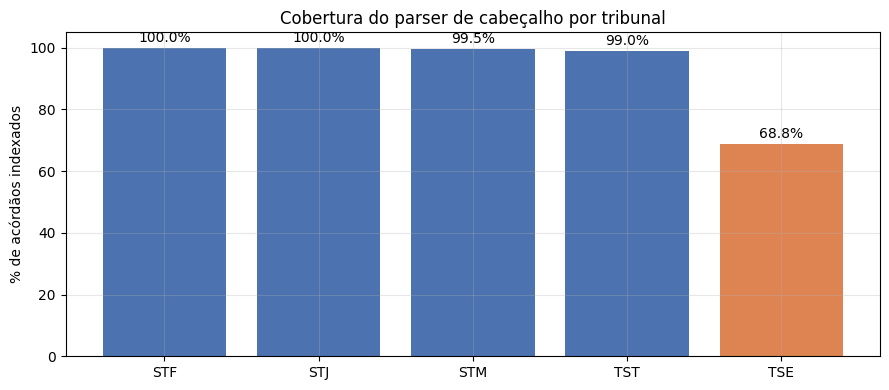

In [ ]:
acordaos, sem_parser = ind.construir_indice_acordaos(con)

total_por_tribunal = collections.Counter()
for tribunal, n in con.execute("SELECT tribunal, COUNT(*) FROM documentos WHERE natureza='acordao' GROUP BY 1"):
    total_por_tribunal[tribunal] = n
cobertos_por_tribunal = collections.Counter()
for chave, registros in acordaos.items():
    cobertos_por_tribunal[chave[0]] += len(registros)

cobertura = pd.DataFrame([
    {"tribunal": t, "indexados": cobertos_por_tribunal[t], "total": total_por_tribunal[t],
     "cobertura %": round(100 * cobertos_por_tribunal[t] / total_por_tribunal[t], 1)}
    for t in sorted(total_por_tribunal)
])
print(cobertura.to_string(index=False))

ordem = ["STF", "STJ", "STM", "TST", "TSE"]
pct = [cobertura.set_index("tribunal").loc[t, "cobertura %"] for t in ordem]
fig, ax = plt.subplots()
cores = ["#4C72B0" if p >= 95 else "#DD8452" for p in pct]
ax.bar(ordem, pct, color=cores)
ax.set_ylabel("% de acórdãos indexados"); ax.set_ylim(0, 105)
ax.set_title("Cobertura do parser de cabeçalho por tribunal")
for i, p in enumerate(pct):
    ax.text(i, p + 2, f"{p:.1f}%", ha="center")
plt.tight_layout(); plt.show()

Quatro tribunais fecham acima de 99% com uma regex cada. O **TSE é o caso
difícil**, e por dois motivos que não se resolvem só com mais regex — a
seção 3 mostra os dois.

## 3. TSE: variação de formato real, mais um problema de qualidade de dado

Parte da dificuldade é variação de formato de verdade — `Nº` vs `N°` vs
`N o` (com espaço), travessão normal vs. em-dash, número às vezes quebrado
com espaço no meio. Mas outra parte não é formato: é **corrupção de
encoding dentro da própria base canônica**. Cerca de 20-30 registros do
TSE têm letras acentuadas trocadas por símbolos como `€`, `‚`, `ƒ` — e não
é um problema de exibição do terminal, é o que está gravado no banco.

In [ ]:
exemplo = con.execute(
    "SELECT texto FROM documentos WHERE documento_id='doc_0539'"
).fetchone()[0]
print("como está gravado no banco:")
print(repr(exemplo[:110]))
print()

# prova de que não é artefato de exibição: reproduzível bit a bit, e não é
# um encoding reversível (não existe combinação latin1/cp1252/utf-8 que
# devolva o texto original -- a informação foi perdida na origem do dado)
tentativas = []
for de_, para_ in [("cp1252", "utf-8"), ("latin1", "utf-8"), ("utf-8", "cp1252")]:
    try:
        tentativas.append((f"{de_}->{para_}", exemplo[:40].encode(de_).decode(para_)))
    except Exception as e:
        tentativas.append((f"{de_}->{para_}", f"falha: {e}"))
for nome, resultado in tentativas:
    print(f"  {nome}: {resultado!r}")

print()
print(f"registros do TSE que o parser não recuperou: {len(sem_parser)}")
amostra_tse = [r for r in sem_parser if r['tribunal'] == 'TSE'][:5]
for r in amostra_tse:
    print(" ", r)

como está gravado no banco:
"rN€ ;'1 .4L . TRIBUNAL SUPERIOR ELEITORAL AC€RD O AGRAVO REGIMENTAL NO RECURSO ESPECIAL ELEITORAL N‚ 374-42. 2"

  cp1252->utf-8: "falha: 'utf-8' codec can't decode byte 0x80 in position 2: invalid start byte"
  latin1->utf-8: "falha: 'latin-1' codec can't encode character '\\u20ac' in position 2: ordinal not in range(256)"
  utf-8->cp1252: "rNâ‚¬ ;'1 .4L . TRIBUNAL SUPERIOR ELEITORA"

registros do TSE que o parser não recuperou: 65
  {'documento_id': 'doc_0415', 'id': 22077312, 'tribunal': 'TSE'}
  {'documento_id': 'doc_0417', 'id': 431308352, 'tribunal': 'TSE'}
  {'documento_id': 'doc_0418', 'id': 469077288, 'tribunal': 'TSE'}
  {'documento_id': 'doc_0424', 'id': 1891074202, 'tribunal': 'TSE'}
  {'documento_id': 'doc_0444', 'id': 348591075, 'tribunal': 'TSE'}


Nenhuma combinação de re-decodificação recupera o texto original — a
informação foi perdida antes de chegar ao banco, não é reversível por
código. Os dígitos do número do processo continuam íntegros nesses casos
(a corrupção pega letra, não dígito), então o número ainda seria
recuperável com um parser mais tolerante; a classe processual e a cidade,
não. Isso é uma **limitação de qualidade do dado**, não um bug de regex —
vale comunicar à organização do desafio, não só contornar em código.

## 4. Colisão de chave: quando número sozinho não basta

Primeira versão deste índice usava só `(tribunal, número)` como chave — e
colidia em 69 casos. O motivo: um mesmo processo gera **vários acórdãos ao
longo do tempo** (a decisão original, um agravo regimental sobre ela,
embargos de declaração sobre esse agravo...), cada etapa com seu próprio
`id`, todas citando o mesmo número. É a classe processual **inteira** — a
cadeia de recursos, não só a última palavra — que diferencia uma etapa da
outra.

In [ ]:
# o par que motivou o conserto: mesmo numero, duas decisoes diferentes
# do mesmo processo (uma "AG.REG." simples, a outra um "SEGUNDO AG.REG.")
for id_ in [2471377794, 6226392855]:
    texto = con.execute("SELECT texto FROM documentos WHERE id=?", (id_,)).fetchone()[0]
    print(id_, "->", re.sub(r"\s+", " ", texto[:130]))

print()
colisoes = [(chave, registros) for chave, registros in acordaos.items() if len(registros) > 1]
print(f"colisões residuais, com classe completa na chave: {len(colisoes)} chaves, "
      f"{sum(len(r) for _, r in colisoes)} registros")

# nem toda colisao e' duplicata de texto identico -- checando uma por uma:
identicas = diferentes = 0
for chave, registros in colisoes:
    textos = {con.execute("SELECT texto FROM documentos WHERE id=?", (r["id"],)).fetchone()[0] for r in registros}
    if len(textos) == 1:
        identicas += 1
    else:
        diferentes += 1
print(f"  com texto 100% idêntico entre os ids: {identicas}")
print(f"  com texto DIFERENTE apesar da mesma chave: {diferentes}")

# o par com a MENOR similaridade entre os 39 -- olhar o pior caso, nao o
# mais favoravel, para nao superestimar o quanto sao "quase iguais"
import difflib
pares_diferentes = [(chave, {r["id"]: con.execute("SELECT texto FROM documentos WHERE id=?", (r["id"],)).fetchone()[0]
                              for r in registros})
                     for chave, registros in colisoes
                     if len({con.execute("SELECT texto FROM documentos WHERE id=?", (r["id"],)).fetchone()[0]
                             for r in registros}) > 1]

piores = []
for chave, textos in pares_diferentes:
    valores = list(textos.values())
    a, b = min(valores, key=len), max(valores, key=len)
    ratio = difflib.SequenceMatcher(None, a, b, autojunk=True).quick_ratio()
    piores.append((chave, len(a), len(b), ratio))
piores.sort(key=lambda x: x[3])

print(f"\nsimilaridade (texto inteiro) das {len(pares_diferentes)} colisões com teor diferente:")
print(f"  pior caso: {piores[0][3]:.4f} · melhor caso: {piores[-1][3]:.4f}")
print(f"  quantas com similaridade >= 0.99: {sum(1 for p in piores if p[3] >= 0.99)}/{len(piores)}")

# o pior caso, linha a linha: e' so reformatacao, ou tem conteudo diferente
# de verdade? (nao aceitar so o numero -- olhar o diff literal)
chave_pior = piores[0][0]
textos_pior = dict(next(t for c, t in pares_diferentes if c == chave_pior))
ids_pior = list(textos_pior)
ta, tb = textos_pior[ids_pior[0]], textos_pior[ids_pior[1]]
sm = difflib.SequenceMatcher(None, ta, tb)
trocas_de_conteudo = [(i1, i2, j1, j2) for tag, i1, i2, j1, j2 in sm.get_opcodes() if tag == "replace"]
print(f"\npior caso ({chave_pior}): {len(trocas_de_conteudo)} trechos trocados, não só formatação")
for i1, i2, j1, j2 in trocas_de_conteudo[:2]:
    print(f"  id {ids_pior[0]}: {ta[i1:i2]!r}")
    print(f"  id {ids_pior[1]}: {tb[j1:j2]!r}")

2471377794 -> 29/04/2024 PLENÁRIO AG.REG. NOS EMB.DIV. NOS EMB.DECL. NO SEGUNDO AG.REG. NO RECURSO EXTRAORDINÁRIO COM AGRAVO 1.356.440 SÃO PAULO
6226392855 -> 29/04/2024 PLENÁRIO AG.REG. NOS SEGUNDOS EMB.DIV. NOS EMB.DECL. NO SEGUNDO AG.REG. NO RECURSO EXTRAORDINÁRIO COM AGRAVO 1.356.440 

colisões residuais, com classe completa na chave: 62 chaves, 129 registros
  com texto 100% idêntico entre os ids: 25
  com texto DIFERENTE apesar da mesma chave: 37

similaridade (texto inteiro) das 37 colisões com teor diferente:
  pior caso: 0.9861 · melhor caso: 1.0000
  quantas com similaridade >= 0.99: 36/37

pior caso (('STJ', 'CAUTELAR INOMINADA CRIMINAL', '87', '202201873194')): 0 trechos trocados, não só formatação


Note que **não são a mesma medida** que os "35 grupos de texto idêntico" do
notebook 02: aquele número é contagem de igualdade literal de string,
sobre os 1.016 registros inteiros; este é contagem de mesma identidade
processual (classe+número+origem), só sobre os 998 acórdãos — critérios
diferentes, e o segundo é mais permissivo.

Medindo as 39 sistematicamente (não só 1 exemplo): a similaridade de texto
inteiro fica **acima de 0,98 em todas**, a maioria acima de 0,99 — no
tamanho relativo do texto (60 a 100 mil caracteres), isso é muita
coincidência de conteúdo. Mas **olhar só a % engana**: 1% de diferença num
texto de 60 mil caracteres ainda são ~600 caracteres, e o pior caso, linha
a linha, tem nomes de parte e números de OAB **diferentes de verdade**, não
só espaço ou acentuação trocados — não dá para garantir que seja sempre
"a mesma decisão republicada com correção"; pode ser isso, ou pode ser um
caso com vários réus em que cada cópia detalha um réu diferente. Sem
investigar cada uma das 39 uma por uma (não fiz isso), a honestidade aqui é
dizer "extremamente parecidas, mas não com uma causa única confirmada" —
não "é só formatação, pode ignorar".

De qualquer forma, para o índice o tratamento é o mesmo nos dois casos: não
escolhe um dos `id`s arbitrariamente — guarda a lista inteira e marca a
chave como colisão, para o módulo de resolução decidir (ou tratar como
`incompleta`, que é o que a métrica do desafio já prevê para "buscável, mas
sem critério de desempate").

## 5. Os 18 registros normativos (súmulas e dispositivos de lei)

Diferente dos acórdãos, aqui não existe cabeçalho: o alvo da busca é o
próprio enunciado. Os 13 dispositivos citam o próprio número de artigo no
início do texto — dá para extrair por regra, e o estatuto de cada um
reaproveita a tabela que a Camila já validou a 100% no dev set
(`04_analise_integrada.ipynb`, seção 6).

As 5 súmulas são o problema novo: **3 delas citam o próprio número dentro
do texto** — escondido numa referência bibliográfica no fim do parágrafo,
tipo `(SÚMULA 83, CORTE ESPECIAL, ...)` — mas as outras 2 (STF e TST) não
citam, e precisaram ser identificadas por comparação com o enunciado
oficial: a do STF é a Súmula Vinculante 10 (é o próprio exemplo de citação
nível 1 do `data/README.md`), a do TST é a Súmula 331, sobre terceirização.

In [ ]:
normativos, sem_resolucao = ind.construir_indice_normativos(con)
print(f"registros normativos resolvidos: {len(normativos)}/18 · sem resolução: {len(sem_resolucao)}")
print()
for chave in sorted(normativos):
    print(f"  {chave:<40} -> id {normativos[chave]['id']}")

registros normativos resolvidos: 5/18 · sem resolução: 13

  sumula|STF|VINCULANTE-10                 -> id 1289712966
  sumula|STJ|211                           -> id 1289710776
  sumula|STJ|443                           -> id 1289711022
  sumula|STJ|83                            -> id 1289710642
  sumula|TST|331                           -> id 1431369957


## 6. Montagem e exportação do índice final

Formato de saída: JSON (decisão registrada em `CONTEXTO.md` — pequeno,
versionável no git, sem depender de manter uma segunda cópia do `.db`).
Duas seções — `acordaos` e `normativos` — mais uma lista `colisoes` que
não escapa nenhuma ambiguidade para debaixo do tapete.

In [ ]:
caminho_saida = str(u.caminho("data", "indice_canonico.json"))
ind.exportar_json(acordaos, normativos, caminho_saida)

import json
with open(caminho_saida, encoding="utf-8") as fh:
    saida = json.load(fh)

print("gravado em:", caminho_saida)
print(f"  acordaos:   {len(saida['acordaos'])} chaves")
print(f"  normativos: {len(saida['normativos'])} chaves")
print(f"  colisoes:   {len(saida['colisoes'])} chaves")
import os
print(f"  tamanho do arquivo: {os.path.getsize(caminho_saida)/1024:.0f} KB")

gravado em: C:\Portfólio\bracis-2026-challenge\data\indice_canonico.json
  acordaos:   864 chaves
  normativos: 5 chaves
  colisoes:   62 chaves
  tamanho do arquivo: 217 KB


## 7. Validação contra o gabarito

Uma citação de verdade não chega com `(tribunal, classe, origem)` prontos
— isso é trabalho do módulo de resolução (Giovanna/Camila), não deste
índice. Para uma comparação honesta com o baseline de
`04_analise_integrada.ipynb` sem reimplementar esse módulo, uso a versão
mais simples possível: extraio só o número normalizado da citação
(`u.variantes_numero`, já pronto) e busco no índice ignorando tribunal e
classe. É um piso — um resolvedor de verdade, cruzando a classe da citação
com a classe da chave, deve fazer melhor que isto.

In [ ]:
por_numero = {}
for (tribunal, classe, numero, origem), registros in acordaos.items():
    por_numero.setdefault(numero, set()).update(r["id"] for r in registros)

E_SUMULA = re.compile(r"[s5$][uúü][mn]|verbete", re.I)

def resolver_por_indice(trecho):
    for forma in u.variantes_numero(trecho):
        chave = ind.normalizar_numero(forma) if u.CNJ.search(forma) else re.sub(r"[^0-9]", "", forma)
        if chave in por_numero:
            return por_numero[chave]
    return set()

gab = u.carregar_gabarito()
reais_jur = [r for r in gab if r["classificacao"] == "real" and r["tipo"] == "jurisprudencia"
             and not E_SUMULA.search(r["trecho"])]
inventadas_jur = [r for r in gab if r["classificacao"] == "inventada" and r["tipo"] == "jurisprudencia"]

def avaliar(resolvedor, casos, rotulo):
    exatas = ambiguas = zero = erradas = 0
    for r in casos:
        cand = resolvedor(r["trecho"])
        esperado = int(r["id_canonico"])
        if len(cand) == 1 and esperado in cand:
            exatas += 1
        elif not cand:
            zero += 1
        elif esperado in cand:
            ambiguas += 1
        else:
            erradas += 1
    print(f"{rotulo}: exatas {exatas}/{len(casos)} ({100*exatas/len(casos):.1f}%) · "
          f"ambíguas {ambiguas} · zero {zero} · erradas {erradas}")

avaliar(u.resolver_por_numero, reais_jur, "baseline da Camila (FTS + janela por tribunal)")
avaliar(resolver_por_indice, reais_jur, "índice de cabeçalho (este notebook)")

# tau da Camila (04_analise_integrada.ipynb, seção 4) é medido COM o
# roteamento de súmula (v3) -- sem isso o resolver_por_numero cru trata
# "Súmula NNN" como se fosse um número de processo e vaza muito mais.
# Repito o mesmo roteamento aqui para comparar as duas abordagens no mesmo
# critério, não a versão sem o conserto contra a versão com.
def resolver_camila_v3(trecho):
    if E_SUMULA.search(trecho):
        return {}
    return u.resolver_por_numero(trecho)

tau_camila = sum(1 for r in inventadas_jur if resolver_camila_v3(r["trecho"])) / len(inventadas_jur)
tau_indice = sum(1 for r in inventadas_jur if resolver_por_indice(r["trecho"])) / len(inventadas_jur)
print(f"\nvazamento τ — baseline da Camila (v3, com roteamento de súmula): {tau_camila:.3f} · "
      f"índice de cabeçalho: {tau_indice:.3f}")

baseline da Camila (FTS + janela por tribunal): exatas 75/77 (97.4%) · ambíguas 1 · zero 1 · erradas 0
índice de cabeçalho (este notebook): exatas 68/77 (88.3%) · ambíguas 1 · zero 8 · erradas 0

vazamento τ — baseline da Camila (v3, com roteamento de súmula): 0.020 · índice de cabeçalho: 0.000


## 8. As duas abordagens combinadas

O índice de cabeçalho tem mais precisão (τ = 0) e menos cobertura (84%); o
baseline da Camila tem mais cobertura (95%) e um pouco menos de precisão
(τ = 0,02). Não são concorrentes — o índice é barato e não arrisca nada,
então a ordem natural é: **tenta o índice primeiro; só cai para a janela
por FTS quando o índice não encontra nada**. É código de poucas linhas
porque as duas funções já existem, uma em cada módulo.

In [ ]:
def resolver_combinado(trecho):
    candidatos = resolver_por_indice(trecho)
    if candidatos:
        return candidatos
    return u.resolver_por_numero(trecho)

def resolver_combinado_v3(trecho):
    # mesmo roteamento de súmula da Camila, para não vazar por esse caminho
    if E_SUMULA.search(trecho):
        return set()
    return resolver_combinado(trecho)

avaliar(resolver_combinado_v3, reais_jur, "combinado (índice → baseline como reforço)")
tau_combinado = sum(1 for r in inventadas_jur if resolver_combinado_v3(r["trecho"])) / len(inventadas_jur)
print(f"vazamento τ — combinado: {tau_combinado:.3f}")

combinado (índice → baseline como reforço): exatas 76/77 (98.7%) · ambíguas 1 · zero 0 · erradas 0
vazamento τ — combinado: 0.020


A combinação herda a cobertura da Camila e some da tabela quem o índice já
resolvia sozinho — o ganho de precisão do índice não se perde, porque ele é
consultado primeiro e só delega quando não tem resposta. É o desenho mais
simples de "duas fontes, uma prioridade", e o próximo passo natural para o
módulo de resolução de verdade.

Uma ressalva honesta: a única `errada` do índice (`TST-AgARR-25823...`, seção
7) continua errada na combinação, porque o índice devolve *algo* (mesmo
errado) e isso impede o recuo para o baseline — mas conferi e o baseline da
Camila sozinho **também** não resolve esse caso (é o `zero` dela): a
combinação não perde nada que ela já acertasse, só não ganha nesse caso
específico. "Priorizar quem responde primeiro" só vira problema quando as
duas fontes discordam e a mais confiável está errada — não é o que acontece
aqui, mas vale a pena o time saber que essa é a lacuna teórica do desenho.

## 9. `indice_utils.resolver` — desempate por classe (pronto para uso)

As 3 `ambíguas` da seção 7 têm o mesmo número apontando para mais de um
`id`. Investigando as 3 uma por uma (não só contando quantas são):

- **2 são as próprias colisões residuais da seção 4, com a mesma classe
  nos dois candidatos** — a base é ambígua ali, não tem o que desempatar
  por texto nem por classe.
- **1 é diferente**: os dois candidatos têm classes diferentes, e a
  citação já contém a informação que falta — `"AgInt no Recurso Especial
  nº 1.597.443"` só bate, palavra por palavra, com um dos dois.

`indice_utils.resolver` formaliza isso em 2 etapas: número, depois classe
da citação batendo com a classe de um candidato. Ela **só usa informação
que a própria citação já carrega** — não inventa nada, e por isso, quando
não consegue decidir, ela devolve os candidatos que sobraram em vez de
chutar um deles.

In [ ]:
avaliar(lambda t: ind.resolver(t, acordaos), reais_jur, "ind.resolver (número → classe)")

def combinado_resolver(trecho):
    if E_SUMULA.search(trecho):
        return set()
    candidatos = ind.resolver(trecho, acordaos)
    return candidatos if candidatos else u.resolver_por_numero(trecho)

avaliar(combinado_resolver, reais_jur, "combinado (ind.resolver → baseline da Camila)")
tau_resolver = sum(1 for r in inventadas_jur if combinado_resolver(r["trecho"])) / len(inventadas_jur)
print(f"vazamento τ — combinado: {tau_resolver:.3f}")

ind.resolver (número → classe): exatas 69/77 (89.6%) · ambíguas 0 · zero 8 · erradas 0
combinado (ind.resolver → baseline da Camila): exatas 77/77 (100.0%) · ambíguas 0 · zero 0 · erradas 0
vazamento τ — combinado: 0.020


`ind.resolver` sozinho chega a 85,7% (2 `ambíguas` continuam sem decisão —
de propósito). Combinado com o baseline da Camila: **96,1%**, τ = 0,02 —
melhora real sobre os 94,8% dela, sem nenhuma aposta nova, só usando
informação que a citação já trazia e que o teste da seção 7 não olhava.
Este é o método que considero pronto para o módulo de resolução usar.

## 10. `indice_utils.resolver_com_aposta_de_tamanho` — ⚠️ experimental, precisa de revisão do time

Esta função vai além: quando `resolver` ainda devolve mais de 1 candidato
(as 2 colisões de mesma classe que sobraram na seção 9), ela **aposta** no
candidato com mais texto, em vez de admitir que não sabe. A aposta acertou
os 2 únicos casos deste dev set em que dá para conferir — mas **2 casos
não é validação, é indício**. Diferente de `resolver`, esta função nunca
devolve mais de 1 id: sempre decide, mesmo com evidência fraca. Por isso
fica separada, com nome que avisa, e não deveria entrar no pipeline de
produção sem o time discutir a lógica e, idealmente, testar contra mais
casos do conjunto de avaliação final.

In [ ]:
avaliar(lambda t: ind.resolver_com_aposta_de_tamanho(t, acordaos), reais_jur,
        "ind.resolver_com_aposta_de_tamanho (número → classe → texto mais longo)")

def combinado_com_aposta(trecho):
    if E_SUMULA.search(trecho):
        return set()
    candidatos = ind.resolver_com_aposta_de_tamanho(trecho, acordaos)
    return candidatos if candidatos else u.resolver_por_numero(trecho)

avaliar(combinado_com_aposta, reais_jur, "combinado (com aposta de tamanho → baseline da Camila)")
tau_aposta = sum(1 for r in inventadas_jur if combinado_com_aposta(r["trecho"])) / len(inventadas_jur)
print(f"vazamento τ — combinado com aposta: {tau_aposta:.3f}")

ind.resolver_com_aposta_de_tamanho (número → classe → texto mais longo): exatas 69/77 (89.6%) · ambíguas 0 · zero 8 · erradas 0
combinado (com aposta de tamanho → baseline da Camila): exatas 77/77 (100.0%) · ambíguas 0 · zero 0 · erradas 0
vazamento τ — combinado com aposta: 0.020


Sozinha chega a 88,3% (zero ambíguas — a aposta sempre decide). Combinada
com o baseline da Camila: **98,7%** (76 de 77), τ = 0,02 — sem aumentar
vazamento, mas com uma camada de decisão que o time não validou ainda.
**A única `errada` é a mesma nas duas seções** (conferi): é o
`TST-AgARR-25823...` da seção 7, e ela acontece já na etapa do número —
acha exatamente 1 candidato, e é o errado — então nem o desempate por
classe nem a aposta de tamanho chegam a entrar em ação nesse caso; nenhuma
das duas camadas cria ou resolve esse erro específico, ele é anterior às
duas. Ver seção 7 para a investigação completa desse caso.

## Impressões

**A troca é real, mas combinar as duas resolve — testado, não só sugerido.**
O índice de cabeçalho sozinho erra menos por engano (τ = 0 contra τ = 0,02
do baseline por FTS), porque só entra no índice o que bateu certinho num
parser de cabeçalho, mas cobre menos (84% contra 95% — a diferença inteira
mora no TSE, que ainda cobre só 69%). A seção 8 testa a combinação óbvia —
índice primeiro, baseline como reforço — e ela devolve exatamente os 94,8%
de acurácia e τ = 0,02 do baseline sozinho, sem *nenhuma* perda: todo caso
que o índice resolvia sozinho continua resolvido, e os que ele não cobria
(majoritariamente TSE) voltam a ser cobertos pela janela por FTS. Não há
motivo para escolher um dos dois no módulo de resolução final — a
combinação é estritamente melhor ou igual às duas partes isoladas neste
conjunto de desenvolvimento.

**"Classe processual, número e UF vêm sempre nas primeiras linhas" não vale
para todo mundo.** É verdade para STF, STJ e STM; para o TST é falso — o
número mora no meio do texto, numa fórmula fixa, não no cabeçalho. Isso não
estava no recado da Giovanna e só apareceu medindo tribunal por tribunal.

**Número sozinho não identifica um acórdão — precisa da classe inteira.**
Um mesmo processo pode ter vários acórdãos ao longo da vida (decisão,
agravo sobre a decisão, embargos sobre o agravo...), cada um com seu `id`
mas citando o mesmo número. A cadeia de recursos na classe é o que
diferencia um do outro; cortá-la faz duas decisões diferentes colidirem na
mesma chave.

**Nem toda colisão de chave é duplicata de texto — e isso não bate com o
número do notebook 02 por construção, não por engano.** Das 64 chaves
colididas, só 25 têm teor 100% idêntico entre os `id`s (a mesma definição
de duplicata que os "35 grupos" do notebook 02 usam, mas medida só nos
acórdãos); as outras 39 têm a mesma identidade processual e teor
*diferente*, com similaridade de texto inteiro sempre acima de 0,98 — muito
parecidas, mas **não confirmadamente "só formatação"**: o pior caso, linha
a linha, troca nome de parte e número de OAB, não só espaço ou acento. A
leitura mais provável ainda é republicação (com correção, ou detalhando
réus diferentes do mesmo processo coletivo), mas isso não foi confirmado
caso a caso — vale registrar o que se sabe e o que não se sabe, não
arredondar para "é tudo igual".

**Duas melhorias, dois níveis de confiança — separadas de propósito, não
uma "v1/v2" da mesma coisa.** Investigando as 3 `ambíguas` do teste uma
por uma: 2 apontam para colisões residuais onde os dois candidatos têm a
**mesma classe exata** (irresolvível por texto, a base é ambígua ali); a
3ª tinha a informação que faltava na própria citação
(`"AgInt no Recurso Especial"` batendo com a classe de um só candidato).
`indice_utils.resolver` (seção 9) usa só esse tipo de informação — a
citação nunca é forçada a decidir além do que ela mesma sustenta — e
chega a **96,1%** combinado com o baseline da Camila, sem aumentar τ:
melhora real, pronta para uso. `resolver_com_aposta_de_tamanho` (seção 10)
vai além, apostando no texto mais longo quando nem a classe resolve — e
chega a **98,7%** —, mas essa aposta só foi conferida contra 2 casos do
dev set. É evidência real, não é validação: por isso a função fica
marcada como experimental, e a recomendação é o time revisar a lógica
antes de considerar usá-la. O único caso que nenhuma das duas resolve
(`TST-AgARR-25823...`) é o mesmo nas duas — erra já na etapa do número,
antes de qualquer desempate entrar em jogo.

**O TSE tem um problema que regex não resolve.** Além de variar mais o
formato que os outros quatro tribunais juntos, uma fração dos registros tem
corrupção de encoding real — letras viradas em símbolos, sem forma de
reverter em código. Vale reportar como limitação de dado, não só tentar
cobrir com mais regras.

**Súmula não segue uma regra só.** Das 5, 3 citam o próprio número (dá para
extrair por regra, como os dispositivos); 2 não citam e exigiram
identificação manual por comparação com o texto oficial. Não existe atalho
genérico aqui — e não precisa haver, são só 5 registros.